# Vulnerability Landscape Analysis

Deep analysis of CVE trends, severity evolution, weakness types, and risk
prioritization using a complete NVD library.

In [1]:
from vulnflow.helpers import CacheBuilder

CACHE_PATH = "../data/complete_library.parquet"

ds = CacheBuilder().ensure(CACHE_PATH)

yearly = ds.count_by("year")
print(f"{len(ds):,} CVEs  |  Year range: {int(yearly['year'].min())}-{int(yearly['year'].max())}")

331,708 CVEs  |  Year range: 1988-2026


## Yearly CVE Growth

TypeError: unsupported operand type(s) for -: 'str' and 'int'

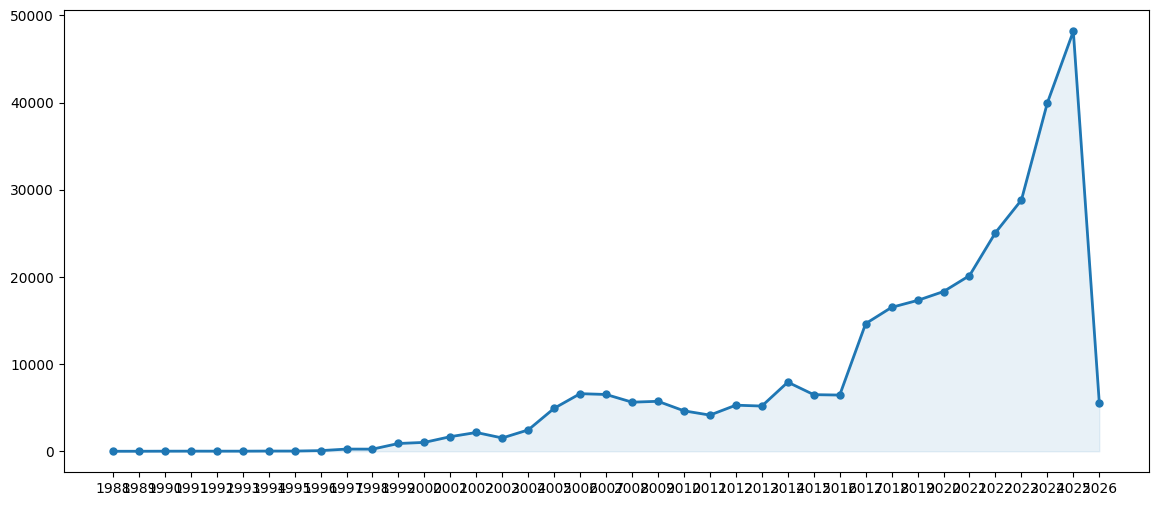

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(yearly["year"], yearly["count"], marker="o", color="#1f77b4", linewidth=2, markersize=5)
ax.fill_between(yearly["year"], yearly["count"], alpha=0.1, color="#1f77b4")

# Annotate key inflection points
peak_year = yearly.loc[yearly["count"].idxmax()]
ax.annotate(
    f"{int(peak_year['year'])}: {int(peak_year['count']):,}",
    xy=(peak_year["year"], peak_year["count"]),
    xytext=(peak_year["year"] - 3, peak_year["count"] + 2000),
    arrowprops=dict(arrowstyle="->", color="#e74c3c"),
    fontsize=11, color="#e74c3c", fontweight="bold",
)

ax.set_title("CVEs Published per Year", fontsize=16)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("CVE Count", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Monthly Trends

In [ ]:
monthly = ds.count_by("month", start="2020-01-01")

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(range(len(monthly)), monthly["count"], color="#1f77b4", linewidth=1.5)
ax.fill_between(range(len(monthly)), monthly["count"], alpha=0.1, color="#1f77b4")

# X-axis labels: show every 6th month
tick_pos = list(range(0, len(monthly), 6))
tick_labels = [str(monthly["month"].iloc[i]) for i in tick_pos]
ax.set_xticks(tick_pos)
ax.set_xticklabels(tick_labels, rotation=45, ha="right")

ax.set_title("Monthly CVE Publications (2020-present)", fontsize=16)
ax.set_ylabel("CVE Count", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Severity Evolution

In [ ]:
import pandas as pd
import numpy as np

SEVERITY_COLORS = {
    "CRITICAL": "#e74c3c",
    "HIGH": "#f39c12",
    "MEDIUM": "#f1c40f",
    "LOW": "#3498db",
}
SEV_ORDER = ["CRITICAL", "HIGH", "MEDIUM", "LOW"]

df = ds.to_pandas()
df["year"] = pd.to_datetime(df["nvd_published_at"]).dt.year
df_scored = df[df["cvss_base_severity"].isin(SEV_ORDER)]

pivot = df_scored.groupby(["year", "cvss_base_severity"]).size().unstack(fill_value=0)
pivot = pivot.reindex(columns=SEV_ORDER)
# Only show years with meaningful data
pivot = pivot[pivot.sum(axis=1) > 100]

fig, ax = plt.subplots(figsize=(14, 6))
bottom = np.zeros(len(pivot))
for sev in SEV_ORDER:
    if sev in pivot.columns:
        vals = pivot[sev].values.astype(float)
        ax.bar(pivot.index, vals, bottom=bottom, label=sev,
               color=SEVERITY_COLORS[sev], edgecolor="white", width=0.8)
        bottom += vals

ax.set_title("Severity Breakdown by Year", fontsize=16)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("CVE Count", fontsize=12)
ax.legend(fontsize=11, loc="upper left")
ax.grid(True, linestyle="--", alpha=0.5, axis="y")
plt.tight_layout()
plt.show()

## Top Weakness Types (CWE)

In [ ]:
cwe_df = df[df["cwe_id"].notna()].copy()
cwe_counts = (
    cwe_df.groupby(["cwe_id", "cwe_name"])
    .size()
    .sort_values(ascending=False)
    .head(15)
    .reset_index(name="count")
)
labels = [f"{row['cwe_id']}: {row['cwe_name'][:40]}" for _, row in cwe_counts.iterrows()]

fig, ax = plt.subplots(figsize=(14, 6))
ax.barh(labels[::-1], cwe_counts["count"].values[::-1], color="#1f77b4", edgecolor="white")
for i, val in enumerate(cwe_counts["count"].values[::-1]):
    ax.text(val + 50, i, f"{val:,}", va="center", fontsize=10)
ax.set_title("Top 15 CWE Weakness Types", fontsize=16)
ax.set_xlabel("CVE Count", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.5, axis="x")
plt.tight_layout()
plt.show()

## Risk Prioritization: EPSS vs CVSS

In [ ]:
scored = df.dropna(subset=["cvss_base_score", "epss_probability"]).copy()
scored = scored[scored["epss_probability"] > 0]

kev_mask = scored["is_kev"] == True
non_kev = scored[~kev_mask]
kev = scored[kev_mask]

fig, ax = plt.subplots(figsize=(14, 6))

# Non-KEV entries
ax.scatter(
    non_kev["cvss_base_score"], non_kev["epss_probability"],
    c="#1f77b4", alpha=0.15, s=8, edgecolors="none", label="CVE",
)
# KEV entries highlighted
ax.scatter(
    kev["cvss_base_score"], kev["epss_probability"],
    c="#e74c3c", alpha=0.7, s=25, edgecolors="white", linewidths=0.5, label="KEV",
)

ax.set_yscale("log")
ax.axhline(y=0.1, color="grey", linestyle=":", alpha=0.5)
ax.axvline(x=7.0, color="grey", linestyle=":", alpha=0.5)

# Quadrant labels
ax.text(8.5, 0.5, "High CVSS + High EPSS\n(Top priority)", fontsize=9, color="#e74c3c", ha="center")
ax.text(3.5, 0.5, "Low CVSS + High EPSS\n(Underrated risk)", fontsize=9, color="#f39c12", ha="center")
ax.text(8.5, 0.0002, "High CVSS + Low EPSS\n(Theoretical risk)", fontsize=9, color="#95a5a6", ha="center")

ax.set_xlabel("CVSS Base Score", fontsize=12)
ax.set_ylabel("EPSS Probability (log)", fontsize=12)
ax.set_title("Risk Prioritization: EPSS vs CVSS (KEV highlighted)", fontsize=16)
ax.legend(fontsize=11)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Known Exploited Vulnerabilities (KEV)

In [ ]:
kev_df = df[df["is_kev"] == True].copy()
ransomware = kev_df[kev_df["kev_ransomware"] == True]

print(f"KEV entries: {len(kev_df):,}")
print(f"Ransomware-linked: {len(ransomware):,} ({100 * len(ransomware) / max(len(kev_df), 1):.0f}%)")

# KEV severity distribution
kev_sev = kev_df["cvss_base_severity"].value_counts()
kev_sev = kev_sev.reindex([s for s in SEV_ORDER if s in kev_sev.index])
colors = [SEVERITY_COLORS[s] for s in kev_sev.index]

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(kev_sev.index, kev_sev.values, color=colors, edgecolor="white")
for bar, val in zip(bars, kev_sev.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
            f"{val:,}", ha="center", va="bottom", fontsize=12, fontweight="bold")
ax.set_title("KEV Entries by CVSS Severity", fontsize=16)
ax.set_ylabel("Count", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.5, axis="y")
plt.tight_layout()
plt.show()